 **Milestone 1 CIE- Bakery sales  **

Project Overview
This project focuses on analyzing a Bakery sales dataset using Python and the Pandas library. The dataset contains retail transaction details, including customer information, product categories, prices, quantities, payment methods, locations, and transaction dates.

Objectives
Load and understand the retail sales dataset.

* Explore rows, columns, data types, and statistical information.
*  Identify and handle missing values.
*  Perform data cleaning and transformation.
*  Analyze sales patterns and customer purchasing trends.
*  Generate meaningful insights from the dataset.
*  Create visualizations to present the findings.


Tools and Technologies





Python
Google Colab
Pandas
NumPy
Matplotlib
Seaborn


Dataset Information

Dataset name: Bakery sales
File name: Bakery sales.csv
Number of rows: 234005

Number of columns: 7



Expected Outcome



The project aims to clean, explore, and analyze retail sales data to identify useful business insights and present the findings through visualizations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
df = pd.read_csv('/content/Bakery sales.csv')

df.head()

,Unnamed: 0,date,time,ticket_number,article,Quantity,unit_price
0,0,2021-01-02,08:38,150040.0,BAGUETTE,1.0,"0,90 €"
1,1,2021-01-02,08:38,150040.0,PAIN AU CHOCOLAT,3.0,"1,20 €"
2,4,2021-01-02,09:14,150041.0,PAIN AU CHOCOLAT,2.0,"1,20 €"
3,5,2021-01-02,09:14,150041.0,PAIN,1.0,"1,15 €"
4,8,2021-01-02,09:25,150042.0,TRADITIONAL BAGUETTE,5.0,"1,20 €"


Check the Number of Rows and Columns

In [3]:

df.shape


(234005, 7)

Check Data Types and Non-Null Values

In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234005 entries, 0 to 234004
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Unnamed: 0     234005 non-null  int64  
 1   date           234005 non-null  object 
 2   time           234005 non-null  object 
 3   ticket_number  234005 non-null  float64
 4   article        234005 non-null  object 
 5   Quantity       234005 non-null  float64
 6   unit_price     234005 non-null  object 
dtypes: float64(2), int64(1), object(4)
memory usage: 12.5+ MB


Display Statistical Summary

In [5]:

df.describe()


,Unnamed: 0,ticket_number,Quantity
count,234005.000000,234005.000000,234005.000000
mean,255205.035854,219201.258738,1.538377
std,147501.625992,40053.223896,1.289603
min,0.000000,150040.000000,-200.000000
25%,127979.000000,184754.000000,1.000000
50%,254573.000000,218807.000000,1.000000
75%,382911.000000,253927.000000,2.000000
max,511395.000000,288913.000000,200.000000


Identify Missing Values

In [6]:

df.isnull().sum()


,0
Unnamed: 0,0
date,0
time,0
ticket_number,0
article,0
Quantity,0
unit_price,0


In [9]:
df = df.drop("Unnamed: 0", axis=1, errors='ignore')

In [10]:
df["date"] = pd.to_datetime(df["date"])


Handle Missing Numerical Values Using Mean

In [13]:
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].mean())



df['unit_price'] = df['unit_price'].fillna(df['unit_price'].mean())

print("Missing numerical values handled successfully!")

Missing numerical values handled successfully!


Handle Missing Categorical Values

In [14]:
df['article'] = df['article'].fillna(df['article'].mode()[0])

print("Missing categorical values handled successfully!")

Missing categorical values handled successfully!


Check Missing Values After Data Cleaning

In [15]:
df.isnull().sum()

,0
date,0
time,0
ticket_number,0
article,0
Quantity,0
unit_price,0


Display the Cleaned Dataset

In [16]:
df.head()

,date,time,ticket_number,article,Quantity,unit_price
0,2021-01-02,08:38,150040.0,BAGUETTE,1.0,0.90
1,2021-01-02,08:38,150040.0,PAIN AU CHOCOLAT,3.0,1.20
2,2021-01-02,09:14,150041.0,PAIN AU CHOCOLAT,2.0,1.20
3,2021-01-02,09:14,150041.0,PAIN,1.0,1.15
4,2021-01-02,09:25,150042.0,TRADITIONAL BAGUETTE,5.0,1.20


In [19]:
# Calculate 'Total Spent' by multiplying Quantity and unit_price
df['Total Spent'] = df['Quantity'] * df['unit_price']

total_sales = df['Total Spent'].sum()
print("Total Sales:", total_sales)

Total Sales: 558640.85


Analyze Quantity Sold for Each Bakery Product

In [23]:
product_sales = df.groupby('article')['Total Spent'].sum()

print(product_sales)

article
.                            0.0
12 MACARON                 700.0
ARMORICAIN                   7.5
ARTICLE 295                  0.0
BAGUETTE                 20481.4
                          ...   
TROPEZIENNE               1050.5
TROPEZIENNE FRAMBOISE       69.7
TULIPE                       7.0
VIENNOISE                  239.8
VIK BREAD                 9278.6
Name: Total Spent, Length: 149, dtype: float64


In [24]:
product_quantity = df.groupby('article')['Quantity'].sum()

print(product_quantity)

article
.                            7.0
12 MACARON                  70.0
ARMORICAIN                   3.0
ARTICLE 295                  1.0
BAGUETTE                 22053.0
                          ...   
TROPEZIENNE                508.0
TROPEZIENNE FRAMBOISE       33.0
TULIPE                       2.0
VIENNOISE                  218.0
VIK BREAD                 3619.0
Name: Quantity, Length: 149, dtype: float64


Visualize Total Sales for Each Bakery Product Using Bar Chart

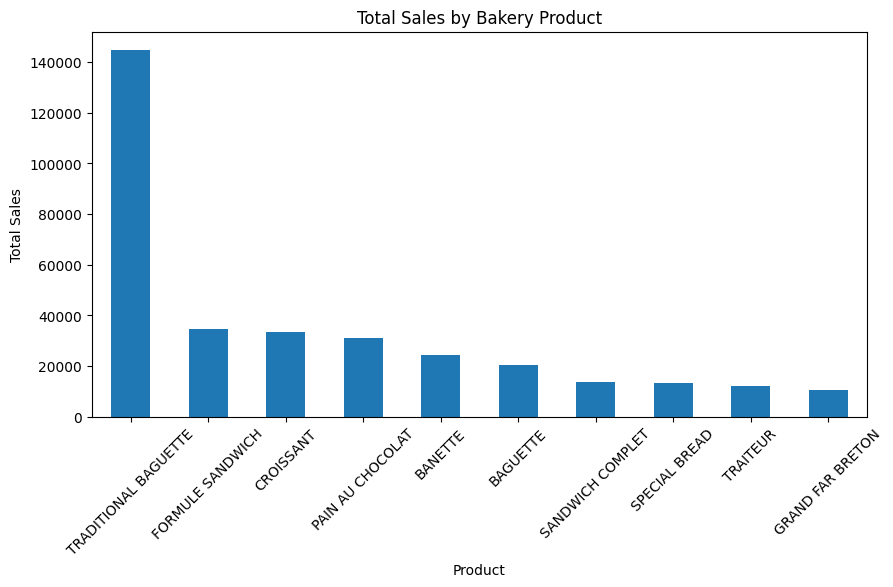

In [25]:
product_sales.sort_values(ascending=False).head(10).plot(kind='bar', figsize=(10, 5))

plt.title('Total Sales by Bakery Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Visualize Bakery Product Sales Using Pie Chart

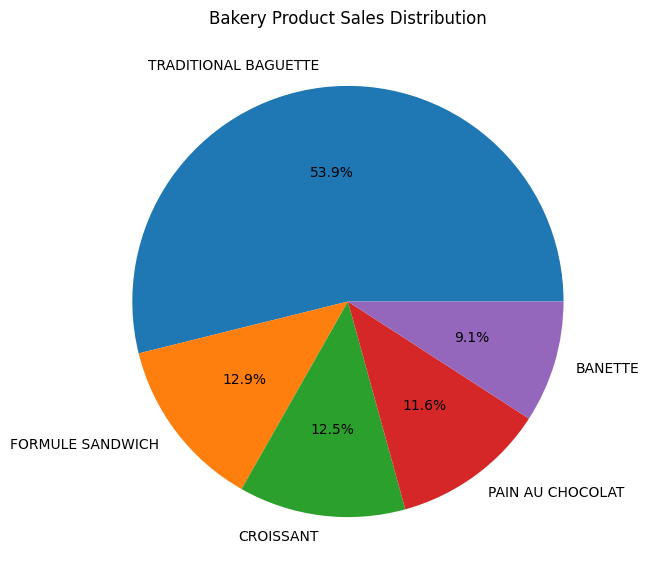

In [26]:
product_sales.sort_values(ascending=False).head(5).plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))

plt.title('Bakery Product Sales Distribution')
plt.ylabel('')
plt.show()

Visualize Top 10 Bakery Products Based on Total Sales

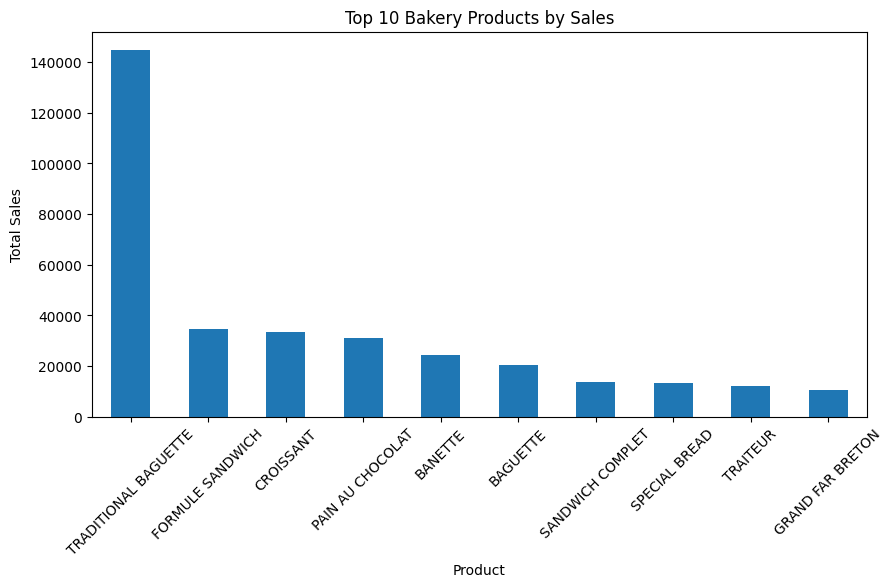

In [27]:
item_sales = df.groupby('article')['Total Spent'].sum().sort_values(ascending=False).head(10)

item_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 Bakery Products by Sales')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Compare Quantity of Products Sold

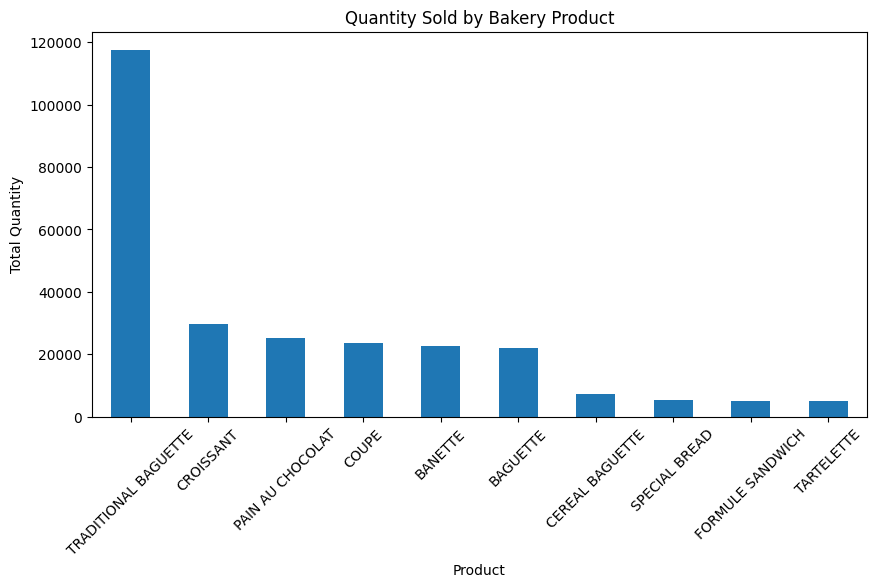

In [28]:
quantity_by_product = df.groupby('article')['Quantity'].sum().sort_values(ascending=False).head(10)

quantity_by_product.plot(kind='bar', figsize=(10, 5))

plt.title('Quantity Sold by Bakery Product')
plt.xlabel('Product')
plt.ylabel('Total Quantity')
plt.xticks(rotation=45)
plt.show()

Analyze Product Price Distribution Using Box Plot

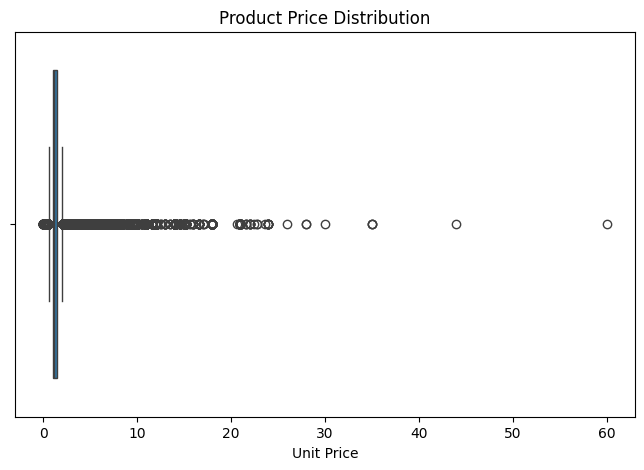

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['unit_price'])

plt.title('Product Price Distribution')
plt.xlabel('Unit Price')
plt.show()

Study Relationship Between Quantity and Total Amount Spent

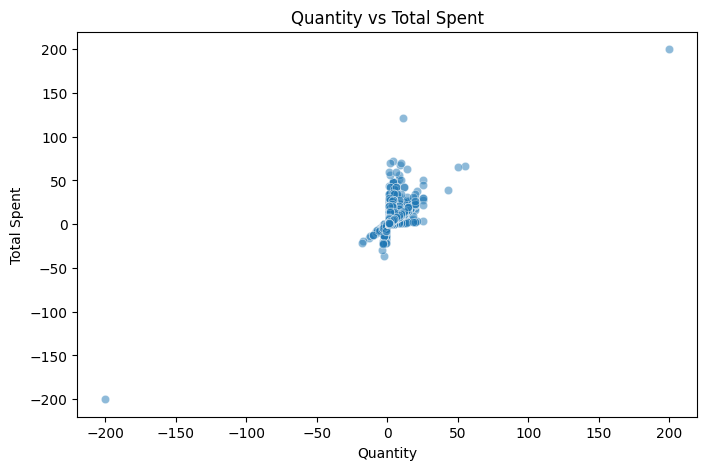

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Quantity', y='Total Spent', alpha=0.5)

plt.title('Quantity vs Total Spent')
plt.xlabel('Quantity')
plt.ylabel('Total Spent')
plt.show()

Visualize Correlation Between Numerical Sales Variables

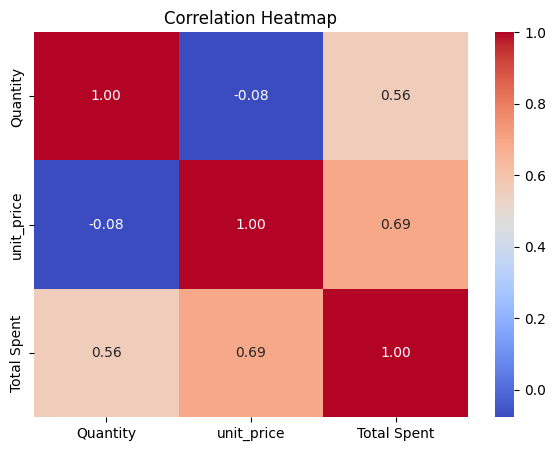

In [31]:
plt.figure(figsize=(7, 5))

correlation = df[['Quantity', 'unit_price', 'Total Spent']].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

Bakery Product Distribution – Donut Chart

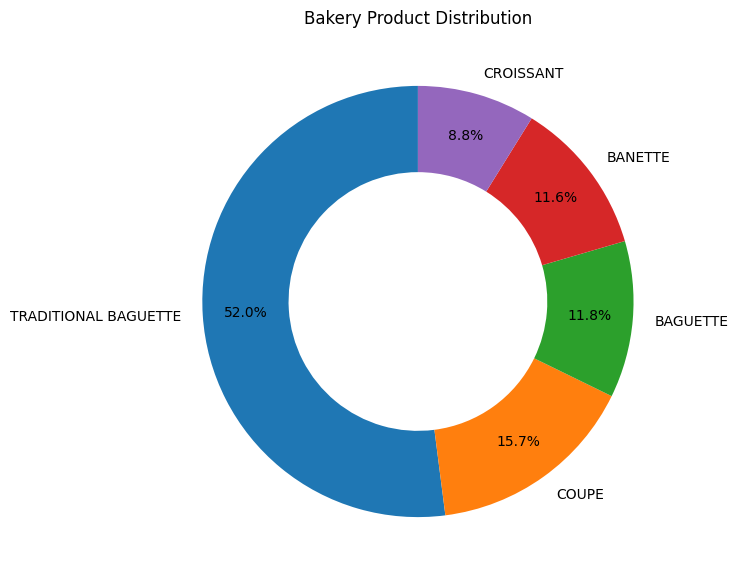

In [32]:
plt.figure(figsize=(7, 7))

product_counts = df['article'].value_counts().head(5)

plt.pie(
    product_counts,
    labels=product_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4},
    pctdistance=0.8
)

plt.title('Bakery Product Distribution')
plt.show()

Analyze Quantity and Total Spent Using Scatter Plot

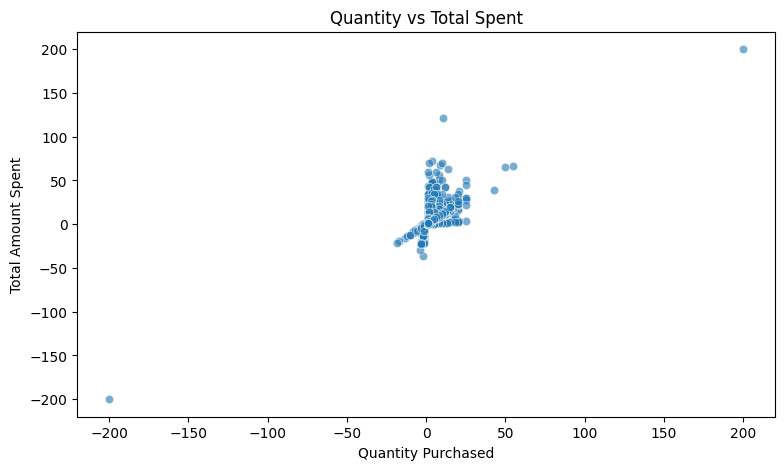

In [33]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total Spent',
    alpha=0.6
)

plt.title('Quantity vs Total Spent')
plt.xlabel('Quantity Purchased')
plt.ylabel('Total Amount Spent')
plt.show()

Visualize Monthly Sales Trends Using Line Chart

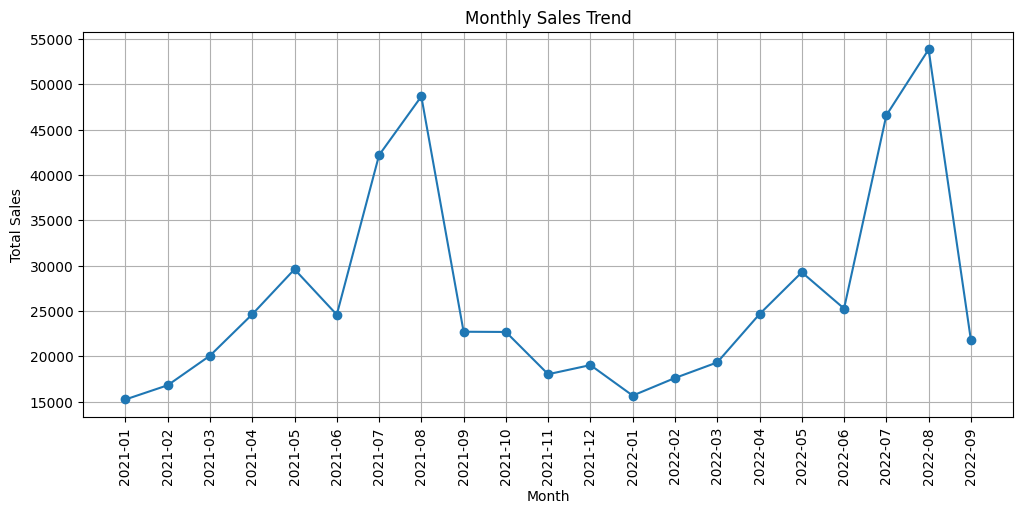

In [34]:
monthly_sales = df.groupby(
    df['date'].dt.to_period('M')
)['Total Spent'].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

Business Insights

In [35]:
print("Total Sales:", round(total_sales, 2))

print("\nBakery Product with Highest Sales:")
print(product_sales.idxmax())

print("\nBakery Product with Lowest Sales:")
print(product_sales.idxmin())

print("\nMost Sold Bakery Product:")
print(product_quantity.idxmax())

print("\nMonthly Sales:")
print(monthly_sales)

Total Sales: 558640.85

Bakery Product with Highest Sales:
TRADITIONAL BAGUETTE

Bakery Product with Lowest Sales:
.

Most Sold Bakery Product:
TRADITIONAL BAGUETTE

Monthly Sales:
date
2021-01    15258.67
2021-02    16827.15
2021-03    20087.60
2021-04    24649.75
2021-05    29617.25
2021-06    24610.25
2021-07    42201.45
2021-08    48680.35
2021-09    22728.80
2021-10    22704.35
2021-11    18043.55
2021-12    19051.15
2022-01    15685.70
2022-02    17627.50
2022-03    19346.61
2022-04    24671.95
2022-05    29286.10
2022-06    25286.30
2022-07    46596.22
2022-08    53857.65
2022-09    21822.50
Name: Total Spent, dtype: float64


Interpretation of Business Insights
- The analysis identifies the bakery product with the highest sales.
- It identifies the bakery product with the lowest sales.
- Product quantity analysis helps identify the most sold bakery product.
- Monthly sales analysis helps understand bakery sales trends over time.
- Product price distribution helps understand the variation in bakery product prices

Conclusion
This project analyzed bakery sales data using Python, Pandas, Matplotlib, and Seaborn.

Data cleaning techniques were used to handle missing values and prepare the dataset for analysis.

Different visualizations helped understand product-wise sales, purchasing patterns, price distribution, and monthly sales trends.

The analysis provided useful insights into bakery sales performance.

This project improved my understanding of data analysis, data visualization, and business insights.

In [36]:
df.to_csv('bakery_sales_cleaned.csv', index=False)